# 01 · Repertoires of the three founding nodes

The common ancestor of the human receptors and the two class ancestors that descend from
it, as the binding model predicts them. Ligands are called by the density fill
(`Downstream_Analysis/scripts/calibration.py`), with no experimental overlay. Repertoire
sizes are relative: compare node against node.

| paper | tree | node |
|---|---|---|
| 0 | `node_1` | common ancestor |
| 1 | `node_2` | class I ancestor |
| 2 | `node_3` | class II ancestor |

Figures use the paper's numbers; tables give the tree id and, where nodes appear, `node_fig`.

In [1]:
import os
import sys
from pathlib import Path

REPO = Path("../..").resolve()
sys.path.append(str(REPO / "Downstream_Analysis/scripts"))
sys.path.append(str(REPO / "scripts"))

from ancestral_sets import ASR_MATRIX, REF_MATRIX, PAIRS, FASTA, ODORS, FIGURES, TABLES

INPUTS = [ASR_MATRIX, REF_MATRIX, PAIRS, FASTA, ODORS]
TABLES_WRITTEN = ["node_sizes", "repertoire_turnover", "nodes_0_to_2_functional_groups",
                  "top_odour_tags"]
FIGURES_WRITTEN = ["pattern_counts", "nodes_0_to_2_descriptors", "nodes_0_to_2_functional_groups"]

for path in INPUTS:
    print("input  ", os.path.relpath(path, REPO))
print("tables ", os.path.relpath(TABLES, REPO), TABLES_WRITTEN)
print("figures", os.path.relpath(FIGURES, REPO), FIGURES_WRITTEN)

input   Downstream_Analysis/predictions/aggregated/ASR_Predictions/asr_median_probability_wide.csv
input   Downstream_Analysis/predictions/aggregated/Reference_Tree_Predictions/reference_median_probability_wide.csv
input   Model_Inputs/Data_Preparation/processed/m2or_pairs_model.csv
input   Phylogenetic_Analysis/data/ReferenceTree/PF13853.9606_7955_7740_7764_75743_137246.fa
input   Chemicals/processed_data/m2or_inchi_odors_smiles.csv
tables  Downstream_Analysis/ancestral_receptors/results ['node_sizes', 'repertoire_turnover', 'nodes_0_to_2_functional_groups', 'top_odour_tags']
figures Downstream_Analysis/ancestral_receptors/figures ['pattern_counts', 'nodes_0_to_2_descriptors', 'nodes_0_to_2_functional_groups']


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import kruskal, fisher_exact

from plotting_functions import custom_plots, FIGSIZE
from ancestral_figures import violin
from ancestral_sets import (load_ancestral, functional_groups, descriptors, odor_tags,
                            figure_node, save_fig, save_table,
                            FG_SMARTS, DESCRIPTORS, PATTERN_ORDER, PATTERN_LABELS)
plt.rcParams.update(custom_plots())

COMMON_COL, CLASS1_COL, CLASS2_COL = "#5F6A72", "#7f1734", "#557c99"
NODE_COL = {"common_ancestor": COMMON_COL, "class1_ancestor": CLASS1_COL,
            "class2_ancestor": CLASS2_COL}
NODE_ID = {"common_ancestor": "node_1", "class1_ancestor": "node_2", "class2_ancestor": "node_3"}

anc = load_ancestral()
print(f"ASR density cut: median probability > {anc.density_cut:.4f}")
for node in anc.per_node_cut:
    print(f"  {node:<18} {int(anc.node_presence[node].sum())} ligands")
print(f"ligands active in at least one node: {len(anc.all_smiles)}")

ASR density cut: median probability > 0.8875
  common_ancestor    21 ligands
  class1_ancestor    21 ligands
  class2_ancestor    8 ligands
ligands active in at least one node: 39


## Repertoire sizes, presence patterns and turnover

Writes `results/node_sizes.csv` and `results/repertoire_turnover.csv` (ligands retained,
lost and gained on each edge out of the common ancestor; Extended Data Fig. 5b). Pattern strings read
[class I, common, class II].

           node node_id  node_fig  probability_cut  n_ligands
common_ancestor  node_1         0         0.887473         21
class1_ancestor  node_2         1         0.887473         21
class2_ancestor  node_3         2         0.887473          8

common           21
class1           21
class2            8
shared_all        2
class1_gains     17
class2_gains      1
class1_losses    17
class2_losses    14


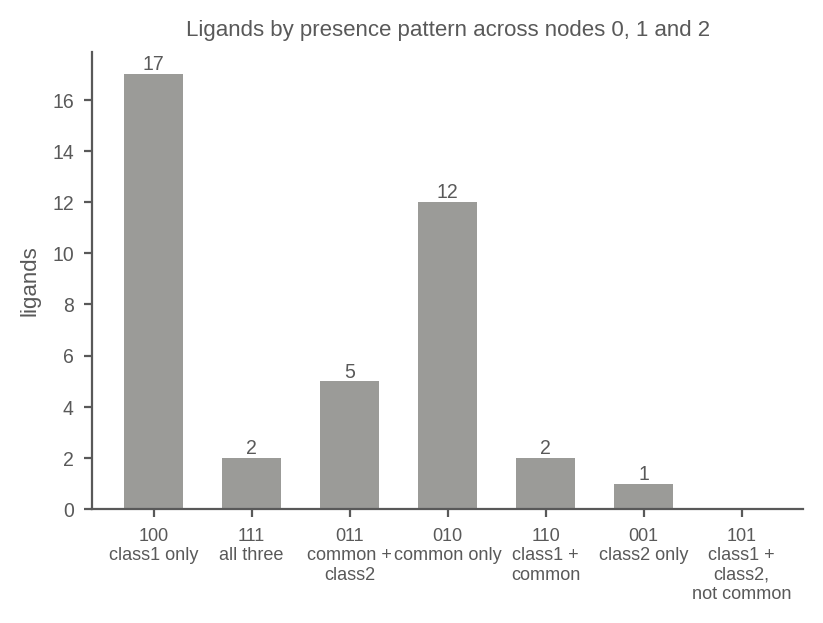

In [3]:
sizes = pd.DataFrame({
    "node": list(anc.per_node_cut),
    "node_id": [NODE_ID[n] for n in anc.per_node_cut],
    "node_fig": [figure_node(NODE_ID[n]) for n in anc.per_node_cut],
    "probability_cut": [anc.per_node_cut[n] for n in anc.per_node_cut],
    "n_ligands": [int(anc.node_presence[n].sum()) for n in anc.per_node_cut],
})
print(sizes.to_string(index=False))
save_table(sizes, "node_sizes")

overlap = pd.Series({k: len(v) for k, v in anc.sets.items()})
print("\n" + overlap.to_string())

counts = [len(anc.pattern_sets[p]) for p in PATTERN_ORDER]
fig, ax = plt.subplots(figsize=FIGSIZE, layout="constrained")
ax.bar(range(len(PATTERN_ORDER)), counts, color="#8a8a86", alpha=0.85, width=0.6)
for i, c in enumerate(counts):
    if c:
        ax.text(i, c, str(c), ha="center", va="bottom")
ax.set_xticks(range(len(PATTERN_ORDER)))
# each pattern's description under its code, one word group per line so neighbours do not collide
ax.set_xticklabels([p + "\n" + PATTERN_LABELS[p].replace(" + ", " +\n").replace(", ", ",\n")
                    for p in PATTERN_ORDER], fontsize=6.5)
ax.set_ylabel("ligands")
ax.set_title("Ligands by presence pattern across nodes 0, 1 and 2")
save_fig(fig, "pattern_counts"); plt.show()

In [4]:
edges = pd.DataFrame({
    "edge": ["node_1 -> node_2", "node_1 -> node_3"],
    "edge_fig": ["0 -> 1", "0 -> 2"],
    "retained": [len(anc.sets["common"] & anc.sets["class1"]),
                 len(anc.sets["common"] & anc.sets["class2"])],
    "lost": [len(anc.sets["class1_losses"]), len(anc.sets["class2_losses"])],
    "gained": [len(anc.sets["class1_gains"]), len(anc.sets["class2_gains"])],
})
print(edges.to_string(index=False))
save_table(edges, "repertoire_turnover")

            edge edge_fig  retained  lost  gained
node_1 -> node_2   0 -> 1         4    17      17
node_1 -> node_3   0 -> 2         7    14       1


## Chemistry of each node's ligand set

RDKit descriptors per node (Kruskal–Wallis across the three), then the share of each
node's ligands carrying each functional group of `scripts/functional_groups.py`, with a
Fisher test of class I against class II. Writes `results/nodes_0_to_2_functional_groups.csv`.

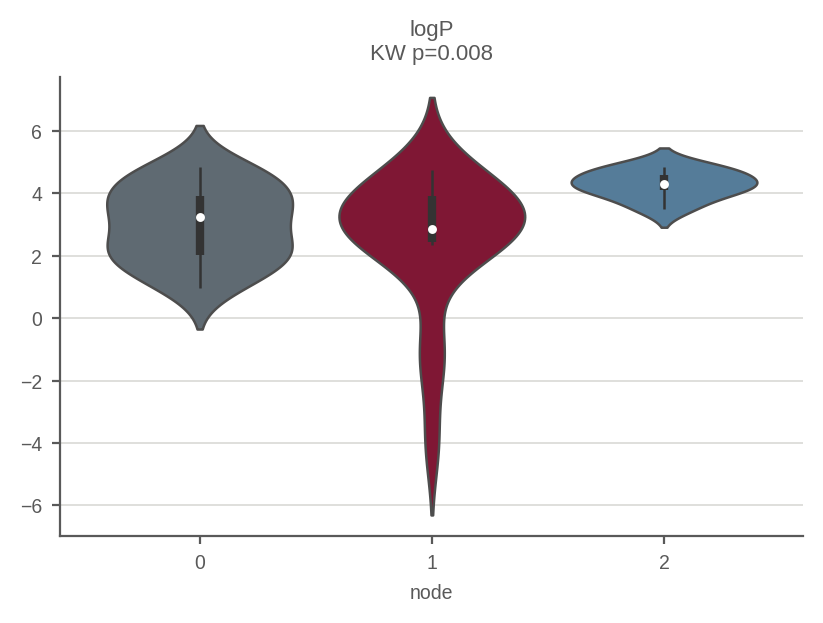

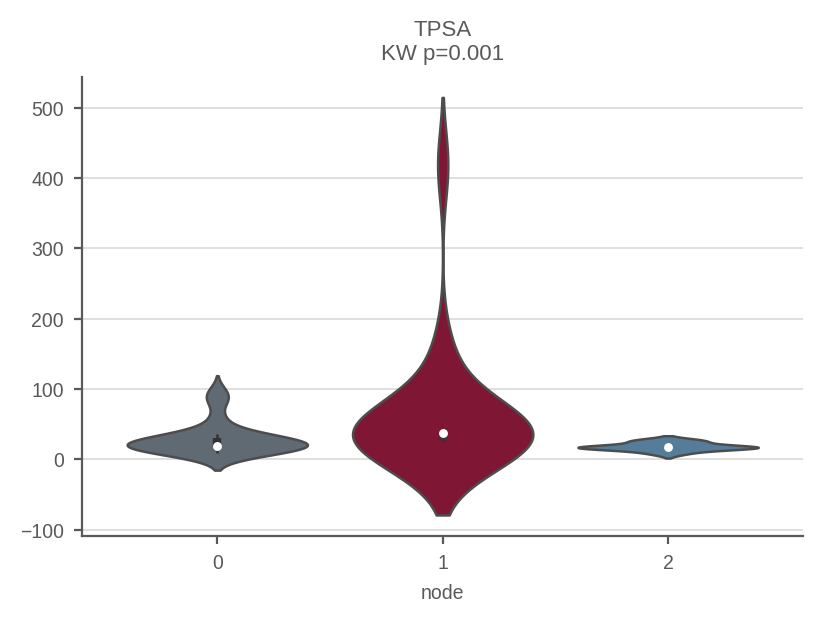

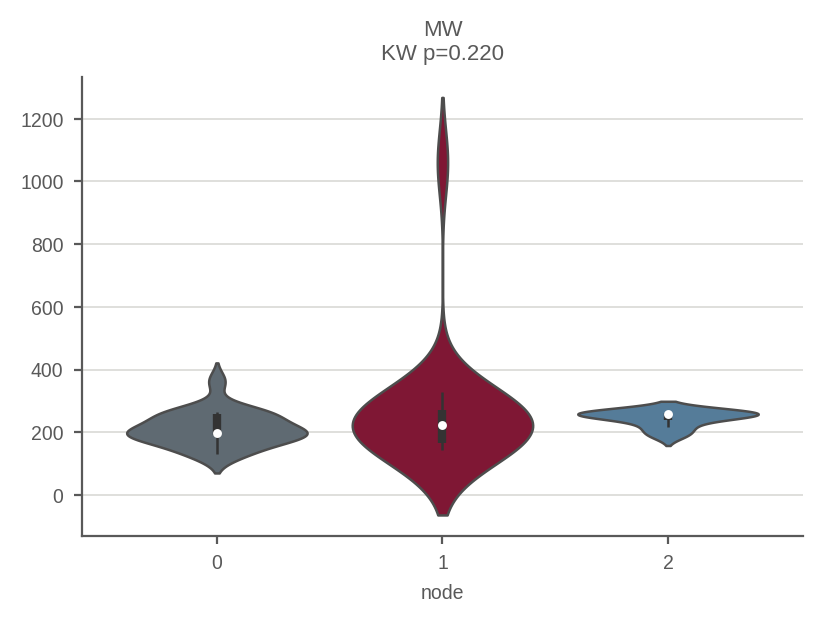

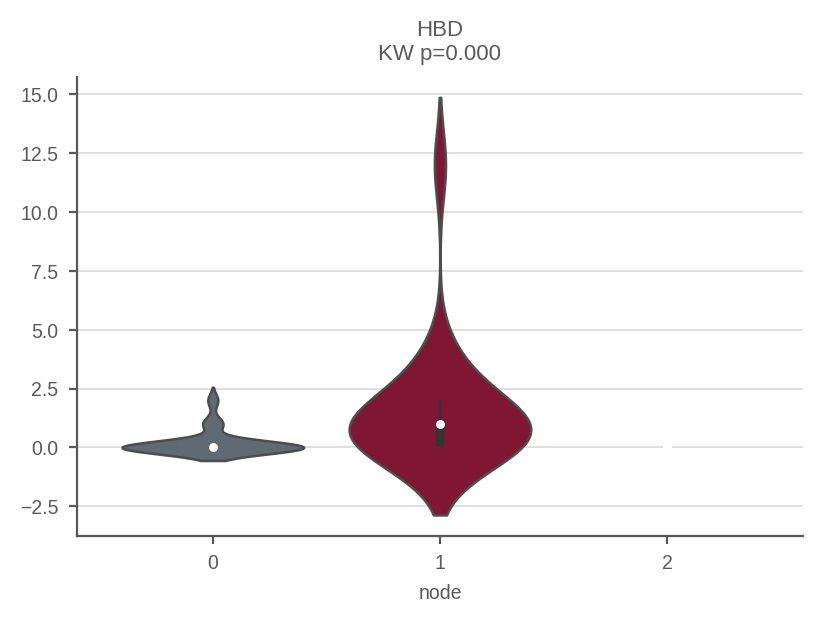

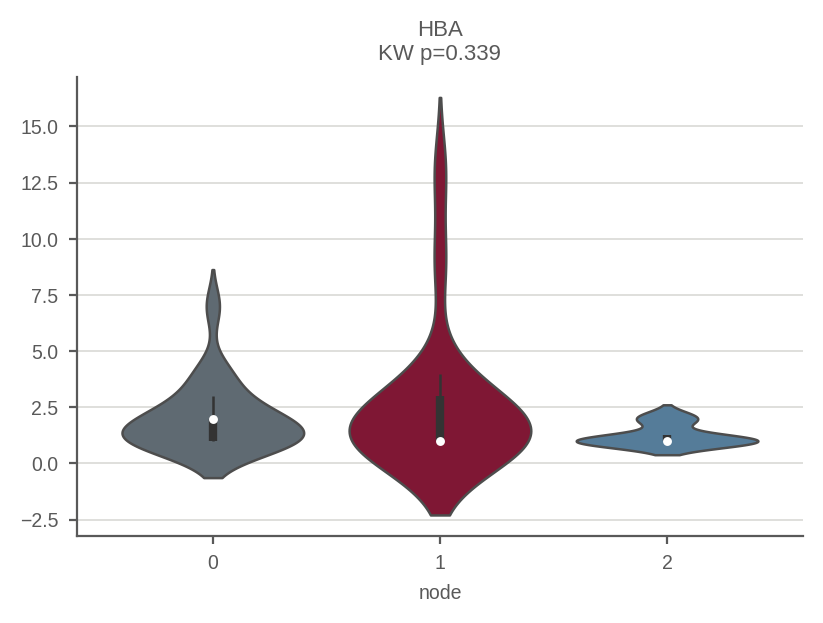

In [5]:
chem = descriptors(anc.all_smiles).merge(functional_groups(anc.all_smiles), on="SMILES")
FG_COLS = list(FG_SMARTS)

node_chem = []
for node in anc.per_node_cut:
    smi = set(anc.node_presence.loc[anc.node_presence[node] == 1, "SMILES"])
    node_chem.append(chem[chem.SMILES.isin(smi)].assign(node=node))
node_chem = pd.concat(node_chem)

figures, axes = zip(*[plt.subplots(figsize=FIGSIZE, layout="constrained") for _ in range(len(DESCRIPTORS))])
for ax, desc in zip(axes, DESCRIPTORS):
    data = [node_chem.loc[node_chem.node == n, desc].dropna().values for n in anc.per_node_cut]
    violin(ax, data, [NODE_COL[n] for n in anc.per_node_cut])
    h, p = kruskal(*data)
    ax.set_title(f"{desc}\nKW p={p:.3f}", fontsize=8)
    ax.set_xticks([1, 2, 3]); ax.set_xticklabels(["0", "1", "2"], fontsize=7)
    ax.set_xlabel("node", fontsize=7)
    ax.tick_params(labelsize=7)
for figure, desc in zip(figures, DESCRIPTORS): save_fig(figure, f"nodes_0_to_2_descriptors_{desc}")
plt.show()

                 common  class1  class2  fisher_p_class1_vs_class2
carboxylic_acid    0.00   47.62     0.0                       0.03
aromatic_ring     61.90   33.33    50.0                       0.43
alkene            57.14   33.33    25.0                       1.00
ether             33.33   19.05    12.5                       1.00
ketone            42.86   14.29    62.5                       0.02
alcohol            4.76   14.29     0.0                       0.54
phenol             4.76   14.29     0.0                       0.54
amine              0.00   14.29     0.0                       0.54
ester             28.57    9.52    25.0                       0.30
aldehyde           4.76    9.52     0.0                       1.00
amide              4.76    4.76     0.0                       1.00
nitrile            0.00    0.00     0.0                       1.00


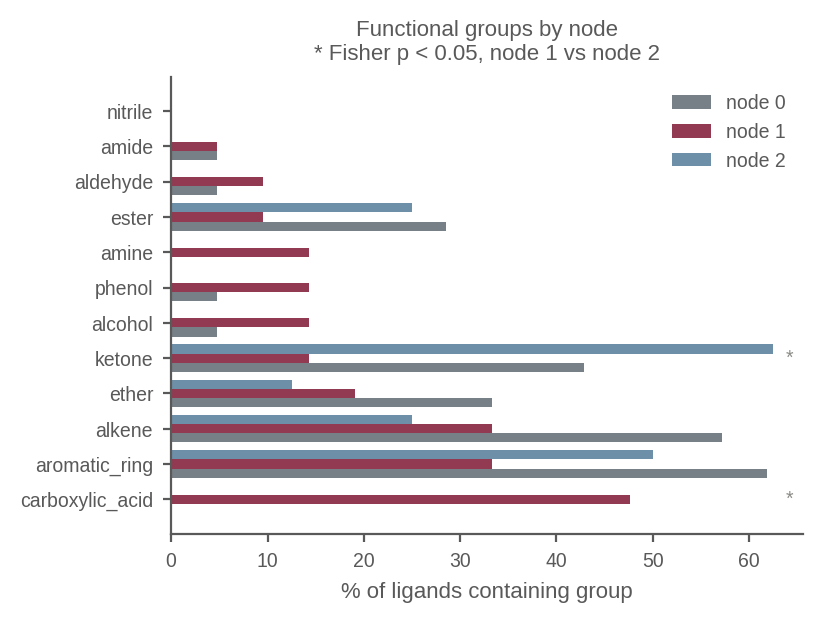

In [6]:
set_of = {"common": anc.sets["common"], "class1": anc.sets["class1"], "class2": anc.sets["class2"]}
prev = pd.DataFrame({g: chem[chem.SMILES.isin(v)][FG_COLS].mean() * 100 for g, v in set_of.items()})
pv = []
for fg in FG_COLS:
    a = chem[chem.SMILES.isin(set_of["class1"])][fg]
    b = chem[chem.SMILES.isin(set_of["class2"])][fg]
    pv.append(fisher_exact([[int(a.sum()), len(a) - int(a.sum())],
                            [int(b.sum()), len(b) - int(b.sum())]])[1])
prev["fisher_p_class1_vs_class2"] = pv
prev = prev.sort_values(["class1", "common"], ascending=False, kind="stable")
print(prev.round(2).to_string())
save_table(prev.reset_index().rename(columns={"index": "functional_group"}),
           "nodes_0_to_2_functional_groups")

show = prev.drop(columns="fisher_p_class1_vs_class2")
fig, ax = plt.subplots(figsize=FIGSIZE, layout="constrained")
y = np.arange(len(show)); w = 0.26
for i, (g, c, label) in enumerate(zip(set_of, [COMMON_COL, CLASS1_COL, CLASS2_COL],
                                      ["node 0", "node 1", "node 2"])):
    ax.barh(y + (i - 1) * w, show[g], w, color=c, alpha=0.85, label=label)
for yi, pval in zip(y, prev["fisher_p_class1_vs_class2"]):
    if pval < 0.05:
        ax.text(show.values.max() * 1.02, yi, "*", va="center", color="#8a8a86")
ax.set_yticks(y); ax.set_yticklabels(show.index)
ax.set_xlabel("% of ligands containing group"); ax.legend()
ax.set_title("Functional groups by node\n* Fisher p < 0.05, node 1 vs node 2")
save_fig(fig, "nodes_0_to_2_functional_groups"); plt.show()

## Odour descriptors per node

The eight most frequent odour tags among each node's ligands (ties broken alphabetically).
Writes `results/top_odour_tags.csv`.

In [7]:
tags = odor_tags()
tag_map = dict(zip(tags.SMILES, tags.tags))

rows = []
for node in anc.per_node_cut:
    smi = sorted(set(anc.node_presence.loc[anc.node_presence[node] == 1, "SMILES"]))
    flat = [t for s in smi for t in tag_map.get(s, [])]
    tag_counts = pd.Series(flat, dtype=str).value_counts().sort_index()
    tag_counts = tag_counts.sort_values(ascending=False, kind="stable").head(8)
    for t, c in tag_counts.items():
        rows.append({"node": node, "tag": t, "n": c})
top_tags = pd.DataFrame(rows)
wide = top_tags.pivot(index="tag", columns="node", values="n").fillna(0).astype(int)
wide = wide[[n for n in anc.per_node_cut if n in wide.columns]]
print(wide.to_string())
save_table(wide.reset_index(), "top_odour_tags")

node     common_ancestor  class1_ancestor  class2_ancestor
tag                                                       
amber                  3                0                3
cheesy                 0                4                0
citrus                 0                3                0
dairy                  0                2                0
dry                    0                0                2
fatty                  0                4                0
floral                 9                2                2
fresh                  0                2                0
fruity                 9                0                3
musk                   4                0                4
powdery                0                0                2
rose                   4                0                0
spicy                  4                0                0
sweet                 17                4                6
waxy                   0                4               